# Stage 2: MLP Classifier for Feature-Based Prediction

This notebook trains a simple **MLP (Multi-Layer Perceptron)** on pre-extracted features  
(e.g., feature maps from Stage 1) to perform classification and evaluates:

- Training / validation loss curves  
- Training / validation accuracy curves  
- Final test accuracy & classification report  
- Confusion matrix heatmap

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

# Make plots inline if in Jupyter
%matplotlib inline

# ----------------------------
# Basic config
# ----------------------------
seed = 42
np.random.seed(seed)
torch.manual_seed(seed)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [11]:
# ============================
# Load FMCE Stage-1 features (single file)
# ============================

import os
from sklearn.model_selection import train_test_split

DATA_DIR = "/content/drive/MyDrive/ExplainableNLP/FMCE_dataset_yahoo_25"

# Feature & label file names
feature_path = os.path.join(DATA_DIR, "fmcs_features_layer-1.npy")
label_path   = os.path.join(DATA_DIR, "fmcs_labels_layer-1.npy")

features = np.load(feature_path)   # shape: [N, D]
labels   = np.load(label_path)     # shape: [N]

print("Features shape:", features.shape)
print("Labels shape  :", labels.shape)

# ----------------------------
# Train / Val / Test split
# ----------------------------
# 70% train, 15% val, 15% test

X_train, X_temp, y_train, y_temp = train_test_split(
    features, labels, test_size=0.30, random_state=42, stratify=labels
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

print("Train:", X_train.shape, y_train.shape)
print("Val  :", X_val.shape, y_val.shape)
print("Test :", X_test.shape, y_test.shape)

# ----------------------------
# If labels do not start from 0 → shift
# ----------------------------
min_label = min(y_train.min(), y_val.min(), y_test.min())
if min_label != 0:
    print(f"Shift labels by -{min_label} to start from 0")
    y_train -= min_label
    y_val   -= min_label
    y_test  -= min_label

num_classes = int(max(y_train.max(), y_val.max(), y_test.max()) + 1)
print("Num classes:", num_classes)


Features shape: (50000, 256)
Labels shape  : (50000,)
Train: (35000, 256) (35000,)
Val  : (7500, 256) (7500,)
Test : (7500, 256) (7500,)
Shift labels by -1 to start from 0
Num classes: 25


In [12]:
# ============================
# Standardize features & create DataLoaders
# ============================

scaler = StandardScaler()

# Fit on training data, transform all
X_train_std = scaler.fit_transform(X_train)
X_val_std   = scaler.transform(X_val)
X_test_std  = scaler.transform(X_test)

# Convert numpy → torch tensors
X_train_tensor = torch.from_numpy(X_train_std).float()
y_train_tensor = torch.from_numpy(y_train).long()

X_val_tensor = torch.from_numpy(X_val_std).float()
y_val_tensor = torch.from_numpy(y_val).long()

X_test_tensor = torch.from_numpy(X_test_std).float()
y_test_tensor = torch.from_numpy(y_test).long()

# Build dataset objects
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset   = TensorDataset(X_val_tensor, y_val_tensor)
test_dataset  = TensorDataset(X_test_tensor, y_test_tensor)

batch_size = 256

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader   = DataLoader(val_dataset,   batch_size=batch_size, shuffle=False)
test_loader  = DataLoader(test_dataset,  batch_size=batch_size, shuffle=False)

input_dim = X_train_tensor.shape[1]
print("Input dim:", input_dim)


Input dim: 256


In [29]:
# ============================
# Define MLP model
# ============================

class MLP(nn.Module):
    def __init__(self, input_dim, hidden_dim=256, num_classes=10, dropout=0.2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, num_classes)
        )

    def forward(self, x):
        return self.net(x)

model = MLP(input_dim=input_dim, hidden_dim=256, num_classes=num_classes, dropout=0.2).to(device)
print(model)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)

MLP(
  (net): Sequential(
    (0): Linear(in_features=256, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=256, out_features=256, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=256, out_features=25, bias=True)
  )
)


In [27]:
# ------------------------
# 4. 定义一个更强的 MLP（两层隐藏层）
# ------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class MLP(nn.Module):
    def __init__(self, input_dim, hidden_dim=256, num_classes=10, dropout=0.2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(hidden_dim, num_classes)
        )

    def forward(self, x):
        return self.net(x)

model = MLP(
    input_dim=input_dim,
    hidden_dim=256,
    num_classes=num_classes,
    dropout=0.2
).to(device)

print(model)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)


MLP(
  (net): Sequential(
    (0): Linear(in_features=256, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=256, out_features=256, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=256, out_features=25, bias=True)
  )
)


In [30]:
# ============================
# Train & validate
# ============================

num_epochs = 100

train_losses = []
val_losses   = []
train_accs   = []
val_accs     = []

def evaluate(loader):
    model.eval()
    all_preds = []
    all_labels = []
    total_loss = 0.0
    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(device)
            yb = yb.to(device)

            logits = model(xb)
            loss = criterion(logits, yb)
            total_loss += loss.item() * xb.size(0)

            preds = logits.argmax(dim=1)
            all_preds.append(preds.cpu().numpy())
            all_labels.append(yb.cpu().numpy())

    all_preds = np.concatenate(all_preds)
    all_labels = np.concatenate(all_labels)

    avg_loss = total_loss / len(loader.dataset)
    acc = accuracy_score(all_labels, all_preds)
    return avg_loss, acc, all_preds, all_labels

best_val_acc = 0.0
best_state_dict = None

for epoch in range(1, num_epochs + 1):
    # ---- Train ----
    model.train()
    running_loss = 0.0
    running_correct = 0
    running_total = 0

    for xb, yb in train_loader:
        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * xb.size(0)
        preds = logits.argmax(dim=1)
        running_correct += (preds == yb).sum().item()
        running_total += xb.size(0)

    train_loss = running_loss / running_total
    train_acc = running_correct / running_total

    # ---- Validation ----
    val_loss, val_acc, _, _ = evaluate(val_loader)

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accs.append(train_acc)
    val_accs.append(val_acc)

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_state_dict = model.state_dict()

    print(f"Epoch [{epoch}/{num_epochs}] "
          f"Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}")

print(f"Best Val Acc: {best_val_acc:.4f}")

Epoch [1/100] Train Loss: 2.2217 Acc: 0.2813 | Val Loss: 1.3947 Acc: 0.5349
Epoch [2/100] Train Loss: 1.2020 Acc: 0.5738 | Val Loss: 0.9335 Acc: 0.6776
Epoch [3/100] Train Loss: 0.9073 Acc: 0.6671 | Val Loss: 0.7725 Acc: 0.7200
Epoch [4/100] Train Loss: 0.7770 Acc: 0.7070 | Val Loss: 0.6927 Acc: 0.7432
Epoch [5/100] Train Loss: 0.7057 Acc: 0.7286 | Val Loss: 0.6457 Acc: 0.7568
Epoch [6/100] Train Loss: 0.6600 Acc: 0.7436 | Val Loss: 0.5986 Acc: 0.7699
Epoch [7/100] Train Loss: 0.6218 Acc: 0.7564 | Val Loss: 0.5844 Acc: 0.7745
Epoch [8/100] Train Loss: 0.5924 Acc: 0.7661 | Val Loss: 0.5599 Acc: 0.7785
Epoch [9/100] Train Loss: 0.5709 Acc: 0.7749 | Val Loss: 0.5341 Acc: 0.7868
Epoch [10/100] Train Loss: 0.5501 Acc: 0.7815 | Val Loss: 0.5031 Acc: 0.7987
Epoch [11/100] Train Loss: 0.5262 Acc: 0.7891 | Val Loss: 0.5045 Acc: 0.7989
Epoch [12/100] Train Loss: 0.5127 Acc: 0.7965 | Val Loss: 0.4858 Acc: 0.8045
Epoch [13/100] Train Loss: 0.5018 Acc: 0.8007 | Val Loss: 0.4737 Acc: 0.8112
Epoch [1

In [31]:
# ============================
# Evaluate on test set
# ============================

if best_state_dict is not None:
    model.load_state_dict(best_state_dict)

test_loss, test_acc, test_preds, test_labels = evaluate(test_loader)

print("\n=== Test Performance ===")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Acc : {test_acc:.4f}")

print("\nClassification Report:")
print(classification_report(test_labels, test_preds, digits=4))


=== Test Performance ===
Test Loss: 0.3774
Test Acc : 0.8487

Classification Report:
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000       300
           1     0.9966    0.9900    0.9933       300
           2     0.9901    0.9967    0.9934       300
           3     0.9967    0.9933    0.9950       300
           4     1.0000    0.9900    0.9950       300
           5     0.9934    1.0000    0.9967       300
           6     0.9967    0.9967    0.9967       300
           7     0.9967    1.0000    0.9983       300
           8     0.9934    1.0000    0.9967       300
           9     0.9966    0.9900    0.9933       300
          10     0.9834    0.9900    0.9867       300
          11     0.9802    0.9900    0.9851       300
          12     0.9834    0.9900    0.9867       300
          13     0.9798    0.9700    0.9749       300
          14     0.9547    0.9833    0.9688       300
          15     0.9796    0.9600    0.9697      

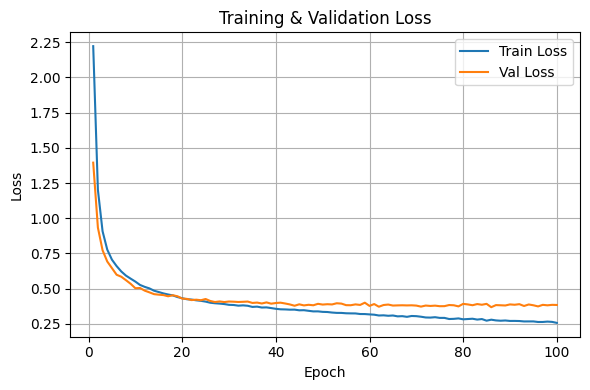

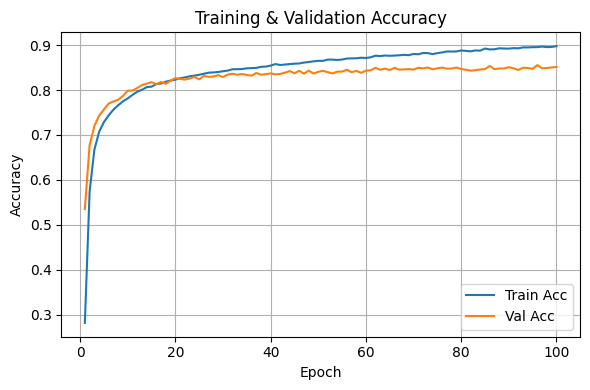

In [32]:
# ============================
# Plot training curves
# ============================

epochs = np.arange(1, len(train_losses) + 1)

plt.figure(figsize=(6,4))
plt.plot(epochs, train_losses, label="Train Loss")
plt.plot(epochs, val_losses,   label="Val Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training & Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(6,4))
plt.plot(epochs, train_accs, label="Train Acc")
plt.plot(epochs, val_accs,   label="Val Acc")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training & Validation Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

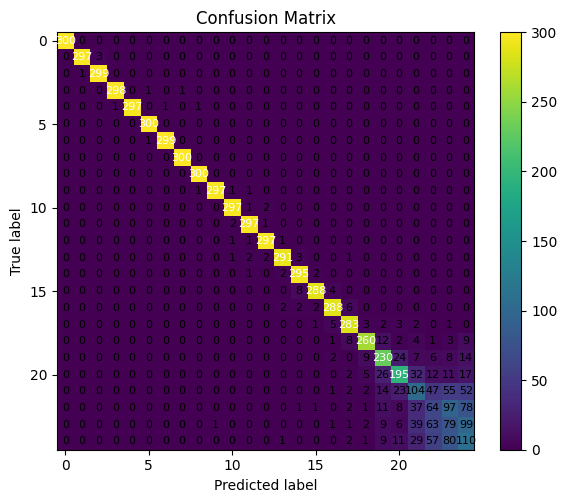

In [33]:
# ============================
# Confusion matrix
# ============================

cm = confusion_matrix(test_labels, test_preds)

plt.figure(figsize=(6,5))
im = plt.imshow(cm, interpolation="nearest")
plt.title("Confusion Matrix")
plt.colorbar(im)
plt.xlabel("Predicted label")
plt.ylabel("True label")

thresh = cm.max() / 2.
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, str(cm[i, j]),
                 ha="center", va="center",
                 color="white" if cm[i, j] > thresh else "black",
                 fontsize=8)

plt.tight_layout()
plt.show()